# Coronary Heart Disease (CHD) Prediction Analysis

This project focuses on using machine learning to predict the risk of non-communicable diseases (NCDs), specifically coronary heart disease (CHD). It applies models such as logistic regression, random forests, XGBoost, and support vector machines (SVM) to assess NCD risk factors based on patient data.

## Table of Contents¶
### 1.Data Loading and Preprocessing
### 2.Exploratory Data Analysis (EDA)
### 3.Data Preparation for Modeling
### 4.Model Development and Evaluation:
     4.1 Logistic Regression
     4.2 K-Nearest Neighbors (KNN)
     4.3 XGBoost
     4.4 Random Forest
     4.5 Support Vector Machine (SVM)

# 1.Data Loading and Preprocessing
### Let's start by importing the necessary libraries and creating functions for each step of our data loading and preprocessing pipeline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV,StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
from sklearn.feature_selection import chi2
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from collections import Counter
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

## 1.1 Load Data
 ### First, let's create a function to load our data:

In [2]:
def load_data(file_path):
    """
    Load the dataset from a CSV file.
    
    Args:
    file_path (str): Path to the CSV file
    
    Returns:
    pd.DataFrame: Loaded dataset
    """
    try:
        df = pd.read_csv(file_path, index_col='Patient ID')
        print(f"Data loaded successfully. Shape: {df.shape}")
        return df
    except FileNotFoundError:
        print(f"File not found: {file_path}")
        return None
    except Exception as e:
        print(f"An error occurred while loading the data: {e}")
        return None

# Usage
file_path = "C:/Users/COCOCE/Downloads/archive (3)/data_cardiovascular_risk.csv"
df = load_data(file_path)

Data loaded successfully. Shape: (3390, 16)


## 1.2 Display Data Info
### Now, let's create a function to display basic information about our dataset:

In [3]:
name= " paci enock"
print (name)
print('..........')
print(name.strip())

 paci enock
..........
paci enock


In [4]:
df.isnull().sum()
df['sex'].nunique()
df.describe()

,age,education,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,Coronary heart disease
count,3390.000000,3303.000000,3368.000000,3346.000000,3390.000000,3390.000000,3390.000000,3352.000000,3390.00000,3390.000000,3376.000000,3389.000000,3086.000000,3390.000000
mean,49.542183,1.970936,9.069477,0.029886,0.006490,0.315339,0.025664,237.074284,132.60118,82.883038,25.794964,75.977279,82.086520,0.150737
std,8.592878,1.019081,11.879078,0.170299,0.080309,0.464719,0.158153,45.247430,22.29203,12.023581,4.115449,11.971868,24.244753,0.357846
min,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.50000,48.000000,15.960000,45.000000,40.000000,0.000000
25%,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.00000,74.500000,23.020000,68.000000,71.000000,0.000000
50%,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.50000,82.000000,25.380000,75.000000,78.000000,0.000000
75%,56.000000,3.000000,20.000000,0.000000,0.000000,1.000000,0.000000,264.000000,144.00000,90.000000,28.040000,83.000000,87.000000,0.000000
max,70.000000,4.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.00000,142.500000,56.800000,143.000000,394.000000,1.000000


In [5]:
df.head(10)

,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,Coronary heart disease
Patient ID,,,,,,,,,,,,,,,,
0,64,2.0,F,YES,3.0,0.0,0,0,0,221.0,148.0,85.0,NaN,90.0,80.0,1
1,36,4.0,M,NO,0.0,0.0,0,1,0,212.0,168.0,98.0,29.77,72.0,75.0,0
2,46,1.0,F,YES,10.0,0.0,0,0,0,250.0,116.0,71.0,20.35,88.0,94.0,0
3,50,1.0,M,YES,20.0,0.0,0,1,0,233.0,158.0,88.0,28.26,68.0,94.0,1
4,64,1.0,F,YES,30.0,0.0,0,0,0,241.0,136.5,85.0,26.42,70.0,77.0,0
5,61,3.0,F,NO,0.0,0.0,0,1,0,272.0,182.0,121.0,32.80,85.0,65.0,1
6,61,1.0,M,NO,0.0,0.0,0,1,0,238.0,232.0,136.0,24.83,75.0,79.0,0
7,36,4.0,M,YES,35.0,0.0,0,0,0,295.0,102.0,68.0,28.15,60.0,63.0,0
8,41,2.0,F,YES,20.0,NaN,0,0,0,220.0,126.0,78.0,20.70,86.0,79.0,0


In [6]:
def display_data_info(df):
    """
    Display basic information about the dataset.
    
    Args:
    df (pd.DataFrame): Input dataset
    """
    print("\nDataset Info:")
    print(df.info())
    
    print("\nDataset Description:")
    print(df.describe())
    
    print("\nMissing Values:")
    print(df.isnull().sum())
    
    print("\nPercentage of Missing Values:")
    print((df.isnull().sum() / len(df) * 100).round(2))

# Usage
display_data_info(df)


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 3390 entries, 0 to 3389
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     3390 non-null   int64  
 1   education               3303 non-null   float64
 2   sex                     3390 non-null   object 
 3   is_smoking              3390 non-null   object 
 4   cigsPerDay              3368 non-null   float64
 5   BPMeds                  3346 non-null   float64
 6   prevalentStroke         3390 non-null   int64  
 7   prevalentHyp            3390 non-null   int64  
 8   diabetes                3390 non-null   int64  
 9   totChol                 3352 non-null   float64
 10  sysBP                   3390 non-null   float64
 11  diaBP                   3390 non-null   float64
 12  BMI                     3376 non-null   float64
 13  heartRate               3389 non-null   float64
 14  glucose                 3086 n

## 1.3 Handle Missing Values
### Let's create a function to handle missing values:

In [7]:
df['education'].unique()

array([ 2.,  4.,  1.,  3., nan])

In [19]:
names=['enock', 'paci', 'jack']
for name in names:
    print(name)

enock
paci
jack


In [4]:
def handle_missing_values(df, strategy='drop'):
    """
    Handle missing values in the dataset.
    
    Args:
    df (pd.DataFrame): Input dataset
    strategy (str): Strategy to handle missing values ('drop' or 'impute')
    
    Returns:
    pd.DataFrame: Dataset with handled missing values
    """
    if strategy == 'drop':
        df_clean = df.dropna()
        print(f"Rows with missing values dropped. New shape: {df_clean.shape}")
    elif strategy == 'impute':
        # Here you can implement various imputation strategies
        # For example, filling numeric columns with mean and categorical columns with mode
        numeric_columns = df.select_dtypes(include=[np.number]).columns
        categorical_columns = df.select_dtypes(exclude=[np.number]).columns
        
        df_clean = df.copy()
        df_clean[numeric_columns] = df_clean[numeric_columns].fillna(df_clean[numeric_columns].mean())
        df_clean[categorical_columns] = df_clean[categorical_columns].fillna(df_clean[categorical_columns].mode().iloc[0])
        
        print(f"Missing values imputed. Shape remains: {df_clean.shape}")
    else:
        raise ValueError("Invalid strategy. Choose 'drop' or 'impute'.")
    
    return df_clean

# Usage
df_clean = handle_missing_values(df, strategy='drop')

Rows with missing values dropped. New shape: (2927, 16)


## 1.4 Encode Categorical Variables
### Next, let's create a function to encode categorical variables:

In [5]:
def encode_categorical_variables(df):
    """
    Encode categorical variables in the dataset.
    
    Args:
    df (pd.DataFrame): Input dataset
    
    Returns:
    pd.DataFrame: Dataset with encoded categorical variables
    """
    le = LabelEncoder()
    categorical_columns = df.select_dtypes(include=['object']).columns
    
    df_encoded = df.copy()
    for col in categorical_columns:
        df_encoded[col] = le.fit_transform(df_encoded[col])
    
    print(f"Categorical variables encoded: {list(categorical_columns)}")
    return df_encoded

# Usage
df_encoded = encode_categorical_variables(df_clean)

Categorical variables encoded: ['sex', 'is_smoking']


# 2. Exploratory Data Analysis (EDA)

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats


## 2.1 Distribution of Numerical Variables


Insights for age:
Mean: 49.51
Median: 49.00
Skewness: 0.23
The distribution of age is approximately symmetric.
Age distribution might indicate the study's focus on a particular age group.

Insights for cigsPerDay:
Mean: 9.11
Median: 0.00
Skewness: 1.19
The distribution of cigsPerDay is positively skewed.

Insights for totChol:
Mean: 237.13
Median: 234.00
Skewness: 0.69
The distribution of totChol is positively skewed.

Insights for sysBP:
Mean: 132.63
Median: 128.50
Skewness: 1.19
The distribution of sysBP is positively skewed.
Blood pressure distributions can help identify hypertension prevalence.

Insights for diaBP:
Mean: 82.91
Median: 82.00
Skewness: 0.70
The distribution of diaBP is positively skewed.
Blood pressure distributions can help identify hypertension prevalence.

Insights for BMI:
Mean: 25.80
Median: 25.38
Skewness: 1.06
The distribution of BMI is positively skewed.
BMI distribution can indicate the overall health status of the population.

Insights for heartRate:
Mean:

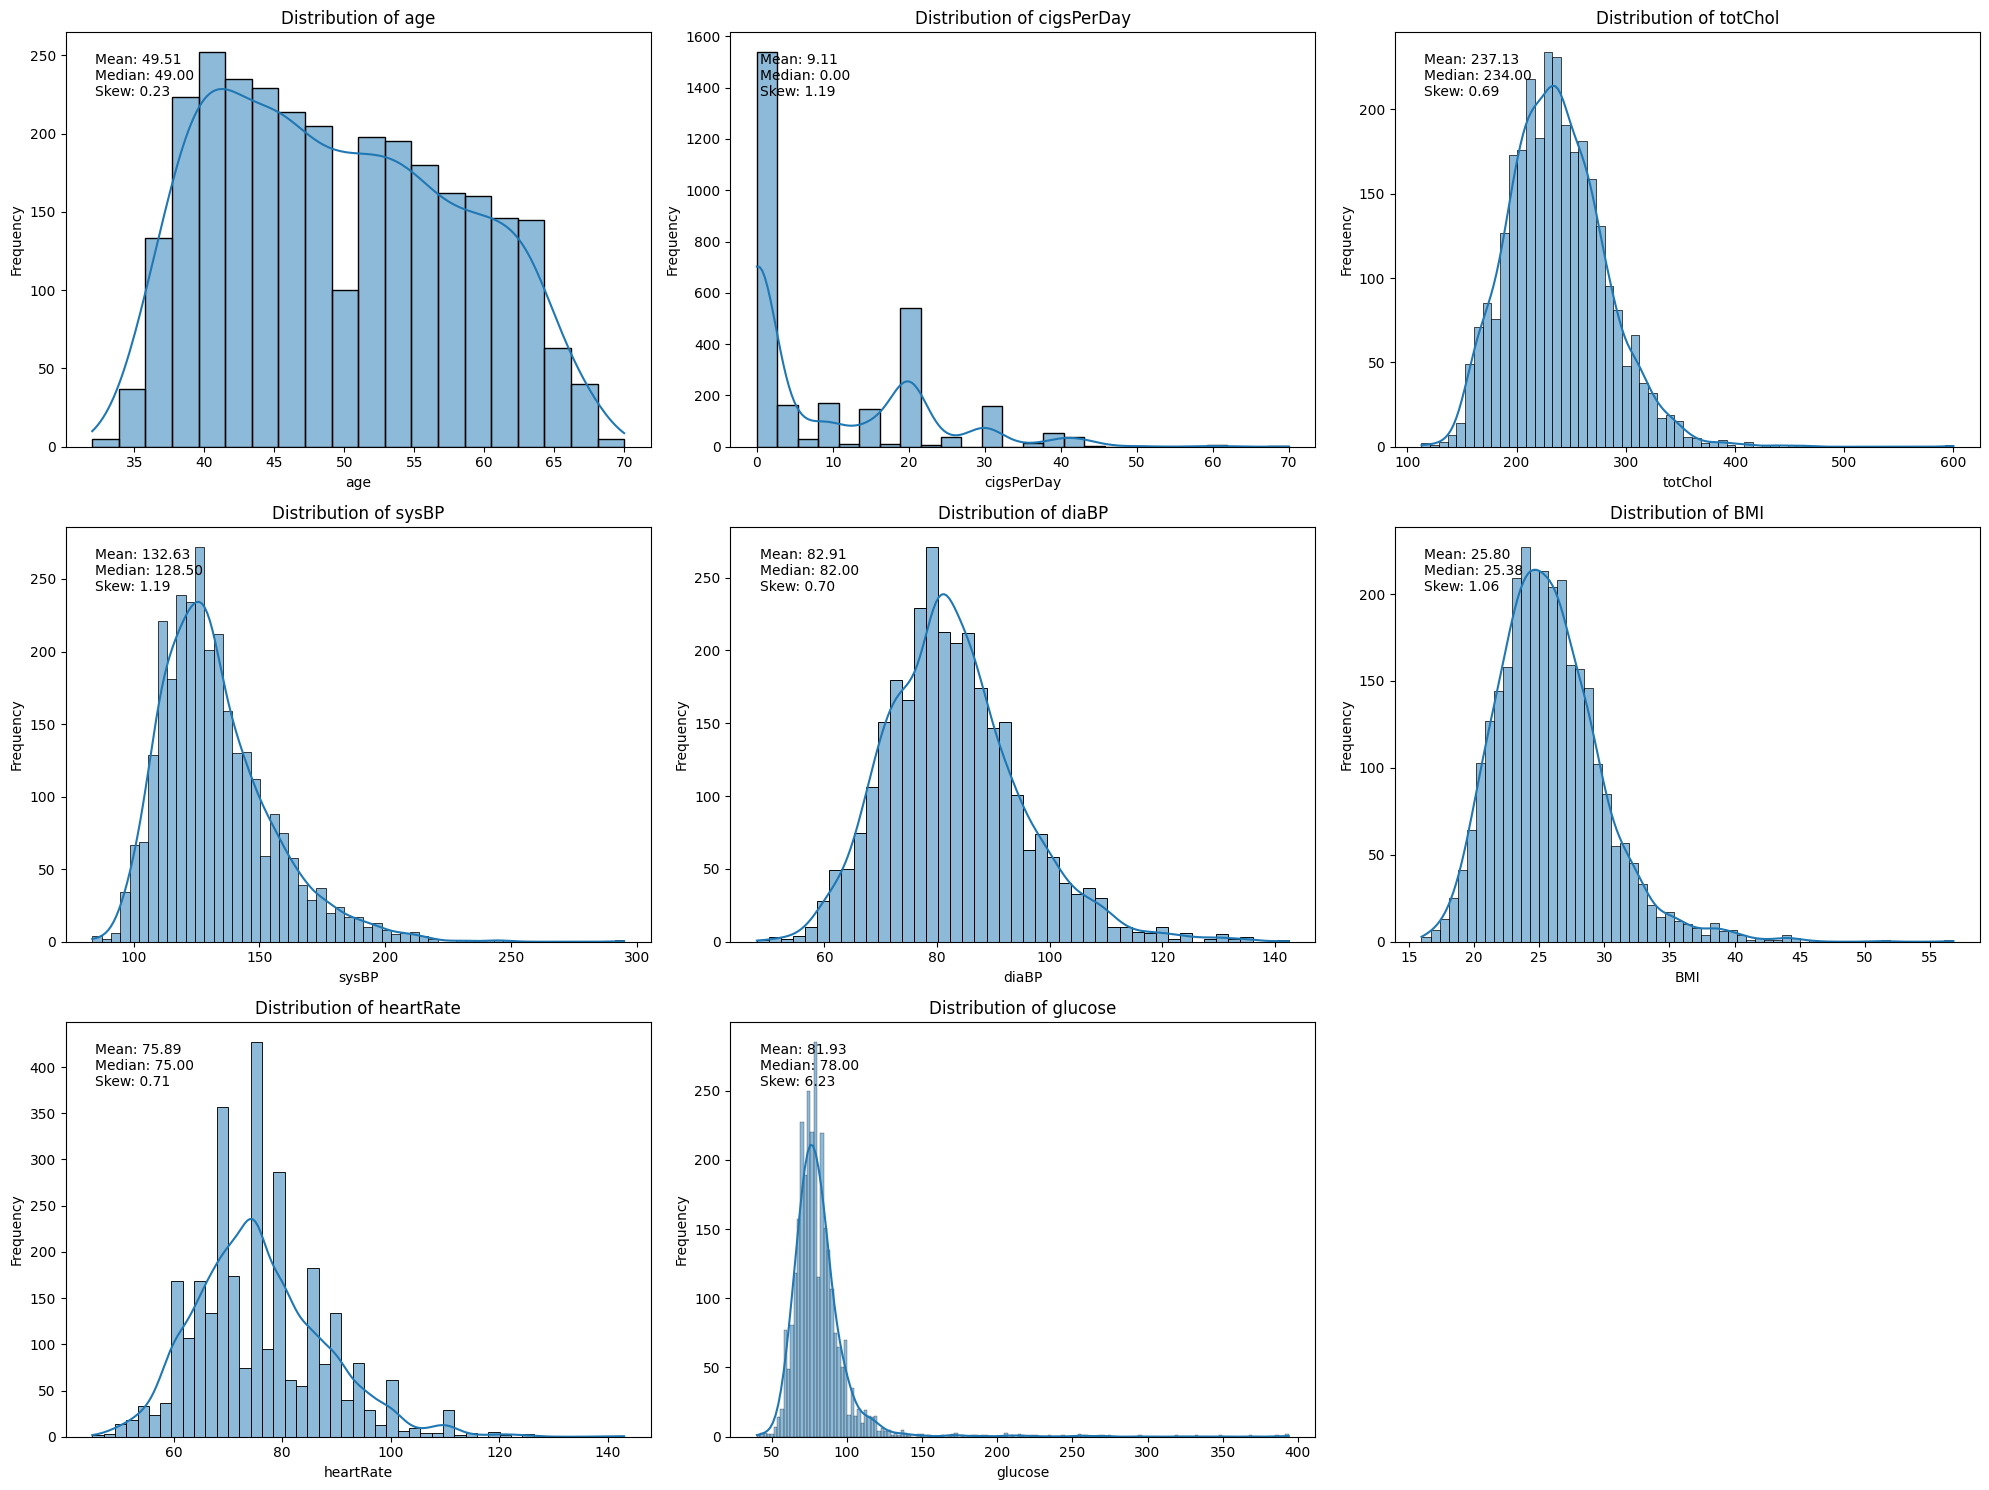

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_numerical_distributions(df, columns):
    """
    Plot the distribution of numerical variables and provide insights.
    
    Args:
    df (pd.DataFrame): Input dataset
    columns (list): List of column names to plot
    """
    n_cols = 3
    n_rows = (len(columns) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
    axes = axes.flatten()
    
    for i, col in enumerate(columns):
        sns.histplot(df[col], kde=True, ax=axes[i])
        axes[i].set_title(f'Distribution of {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')
        
        # Calculate statistics
        mean_val = df[col].mean()
        median_val = df[col].median()
        skew_val = df[col].skew()
        
        # Add text annotations to the plot
        axes[i].text(0.05, 0.95, f"Mean: {mean_val:.2f}\nMedian: {median_val:.2f}\nSkew: {skew_val:.2f}", 
                     transform=axes[i].transAxes, verticalalignment='top')
        
        # Print insights
        print(f"\nInsights for {col}:")
        print(f"Mean: {mean_val:.2f}")
        print(f"Median: {median_val:.2f}")
        print(f"Skewness: {skew_val:.2f}")
        
        if abs(skew_val) > 0.5:
            print(f"The distribution of {col} is {'positively' if skew_val > 0 else 'negatively'} skewed.")
        else:
            print(f"The distribution of {col} is approximately symmetric.")
        
        if col == 'age':
            print("Age distribution might indicate the study's focus on a particular age group.")
        elif col in ['sysBP', 'diaBP']:
            print("Blood pressure distributions can help identify hypertension prevalence.")
        elif col == 'BMI':
            print("BMI distribution can indicate the overall health status of the population.")
        elif col == 'glucose':
            print("Glucose distribution might reveal potential diabetes cases.")
    
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

# Usage example (make sure to define df and numerical_columns before calling this function)
numerical_columns = ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
plot_numerical_distributions(df=df_clean, columns=numerical_columns)

## 2.2 Correlation Heatmap

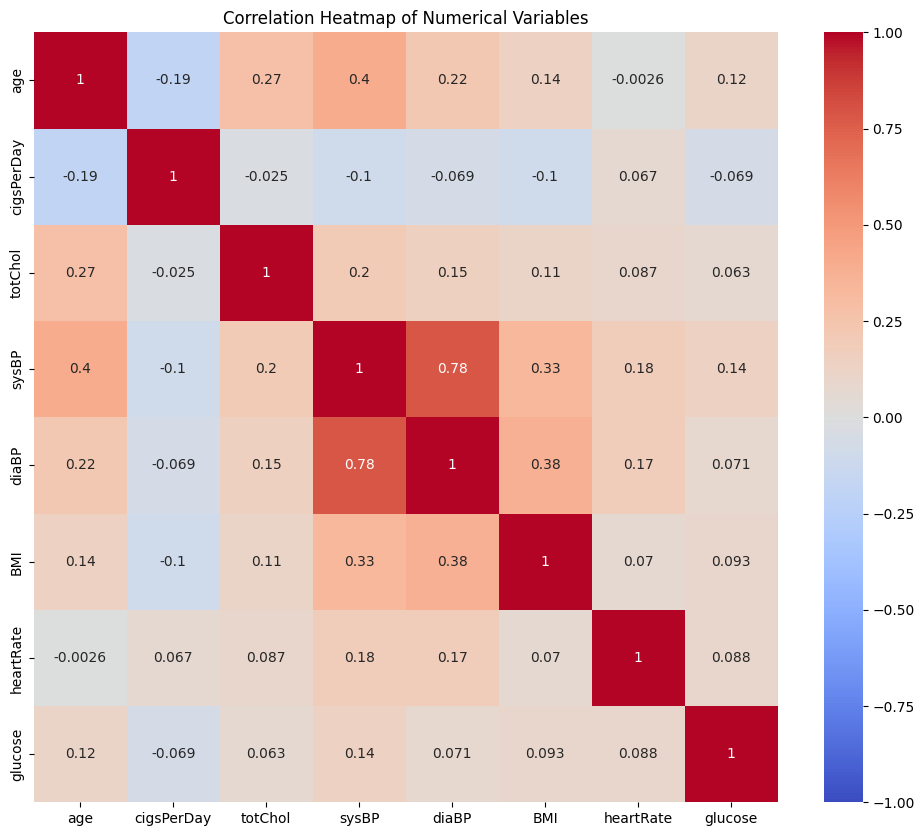


Insights from the correlation heatmap:
Strong positive correlation (0.78) between sysBP and diaBP.
  This is expected as systolic and diastolic blood pressures are related.

Variables with low correlation to others might be independent risk factors.


In [8]:
def plot_correlation_heatmap(df_clean, columns):
    """
    Plot a correlation heatmap for numerical variables and provide insights.
    
    Args:
    df (pd.DataFrame): Input dataset
    columns (list): List of column names to include in the heatmap
    """
    corr = df[columns].corr()
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
    plt.title('Correlation Heatmap of Numerical Variables')
    plt.show()
    
    print("\nInsights from the correlation heatmap:")
    for i in range(len(columns)):
        for j in range(i+1, len(columns)):
            corr_val = corr.iloc[i, j]
            if abs(corr_val) > 0.5:
                print(f"Strong {'positive' if corr_val > 0 else 'negative'} correlation ({corr_val:.2f}) between {columns[i]} and {columns[j]}.")
                if 'BP' in columns[i] and 'BP' in columns[j]:
                    print("  This is expected as systolic and diastolic blood pressures are related.")
                elif 'age' in [columns[i], columns[j]]:
                    print("  This could indicate age-related changes in health metrics.")
    
    print("\nVariables with low correlation to others might be independent risk factors.")
numerical_columns = ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
plot_correlation_heatmap(df_clean, columns=numerical_columns)

## 2.3 Categorical Variable Analysis

Analyzing categorical variable distributions:


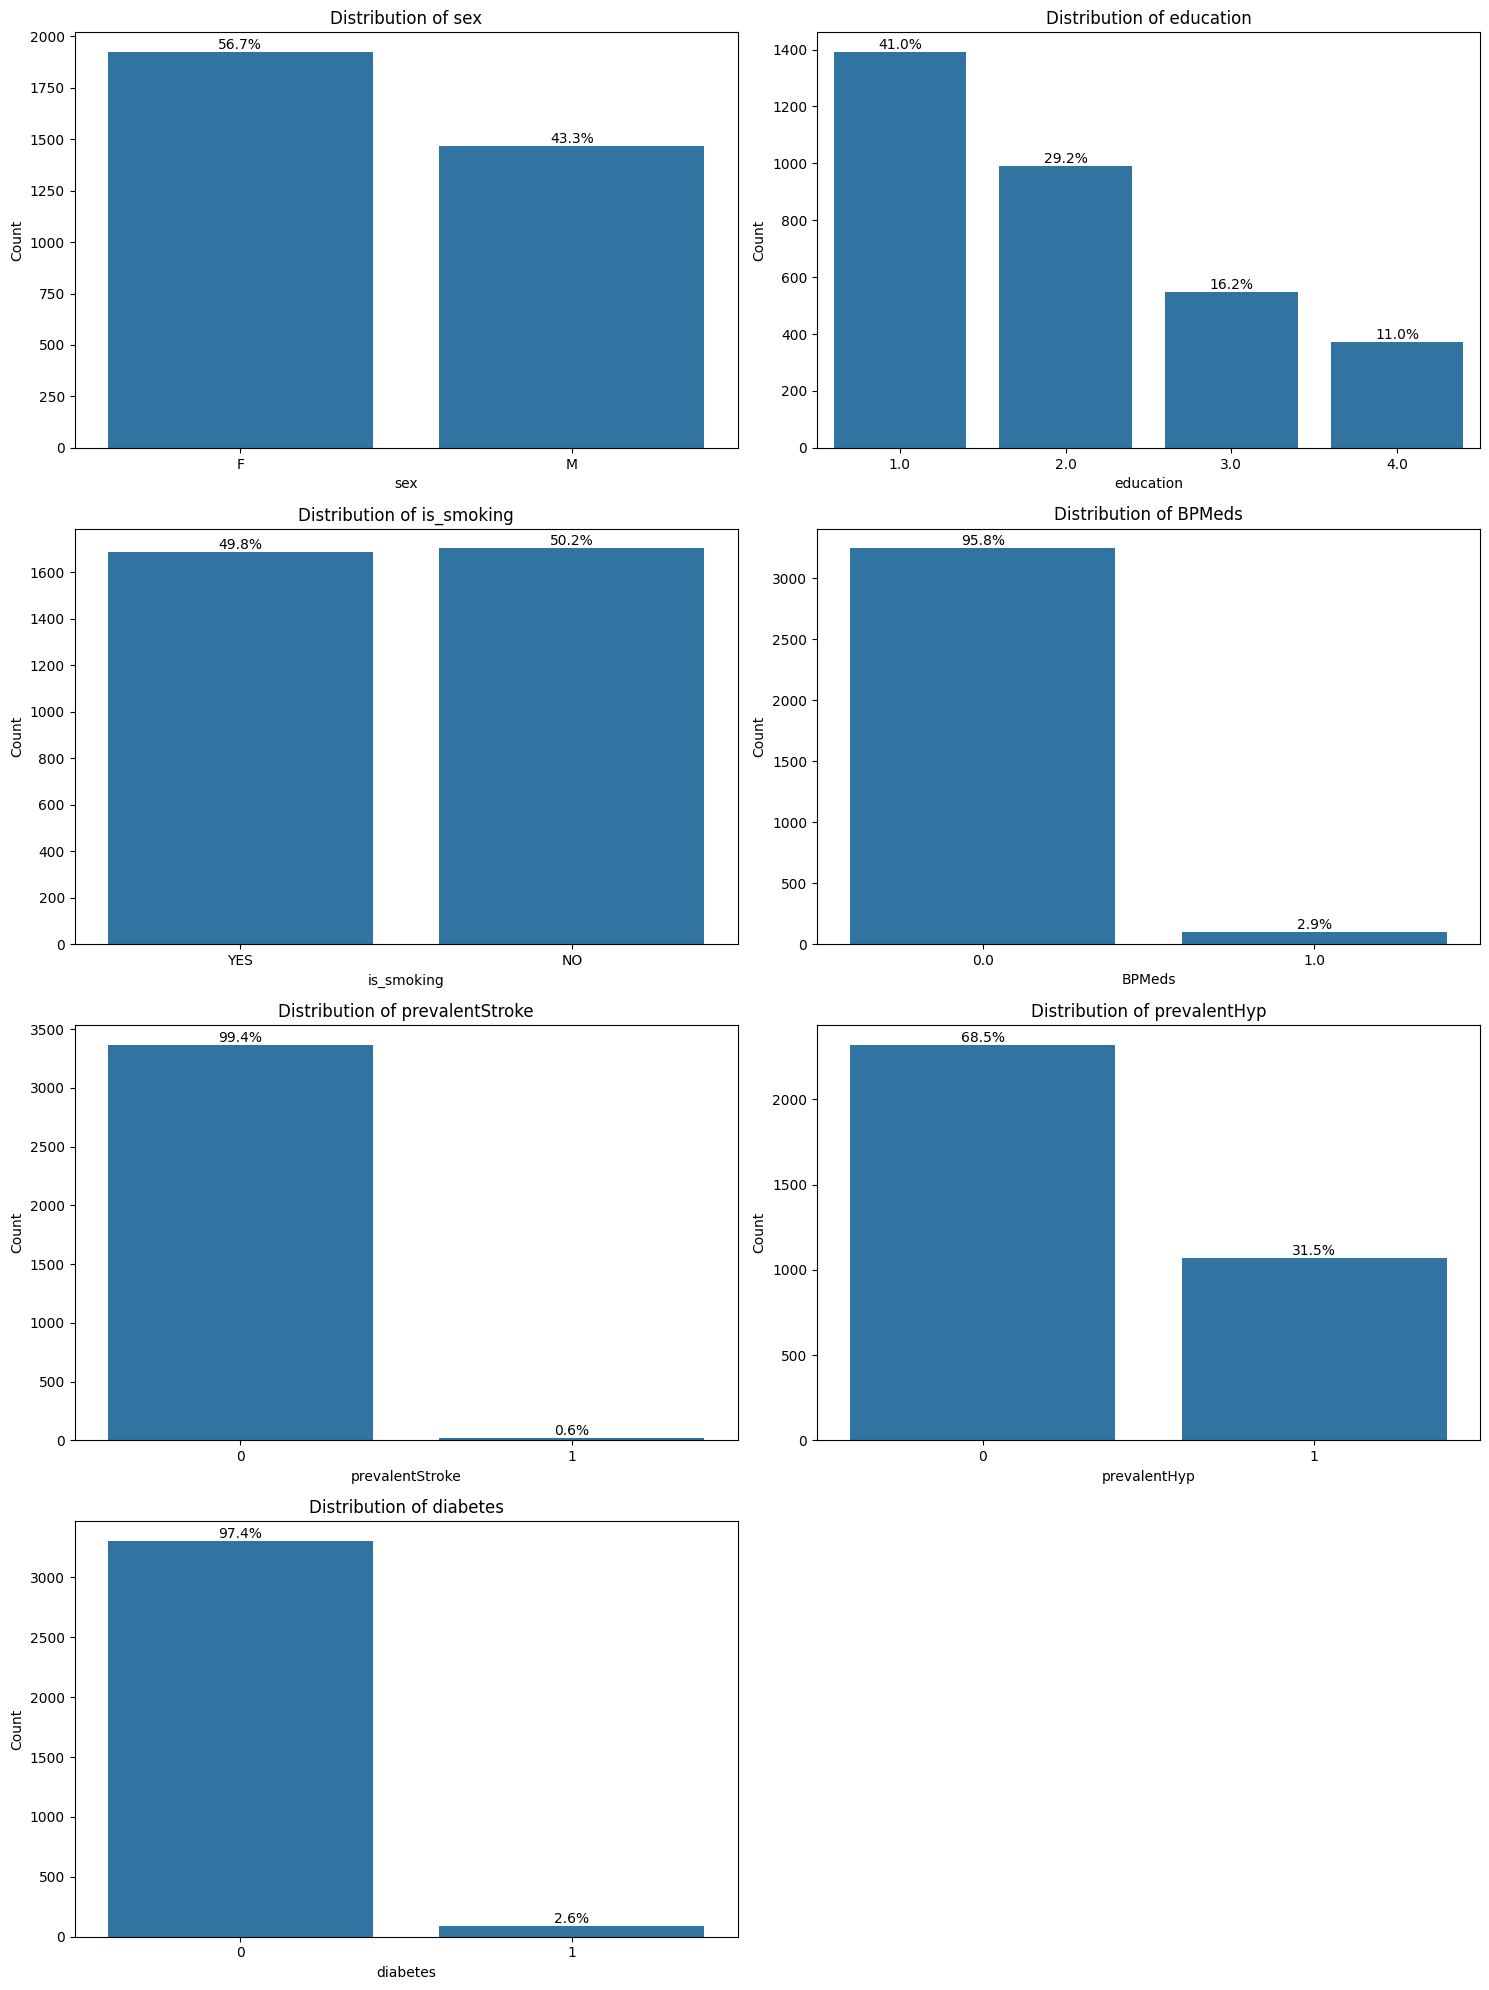


Analyzing categorical variables vs target:


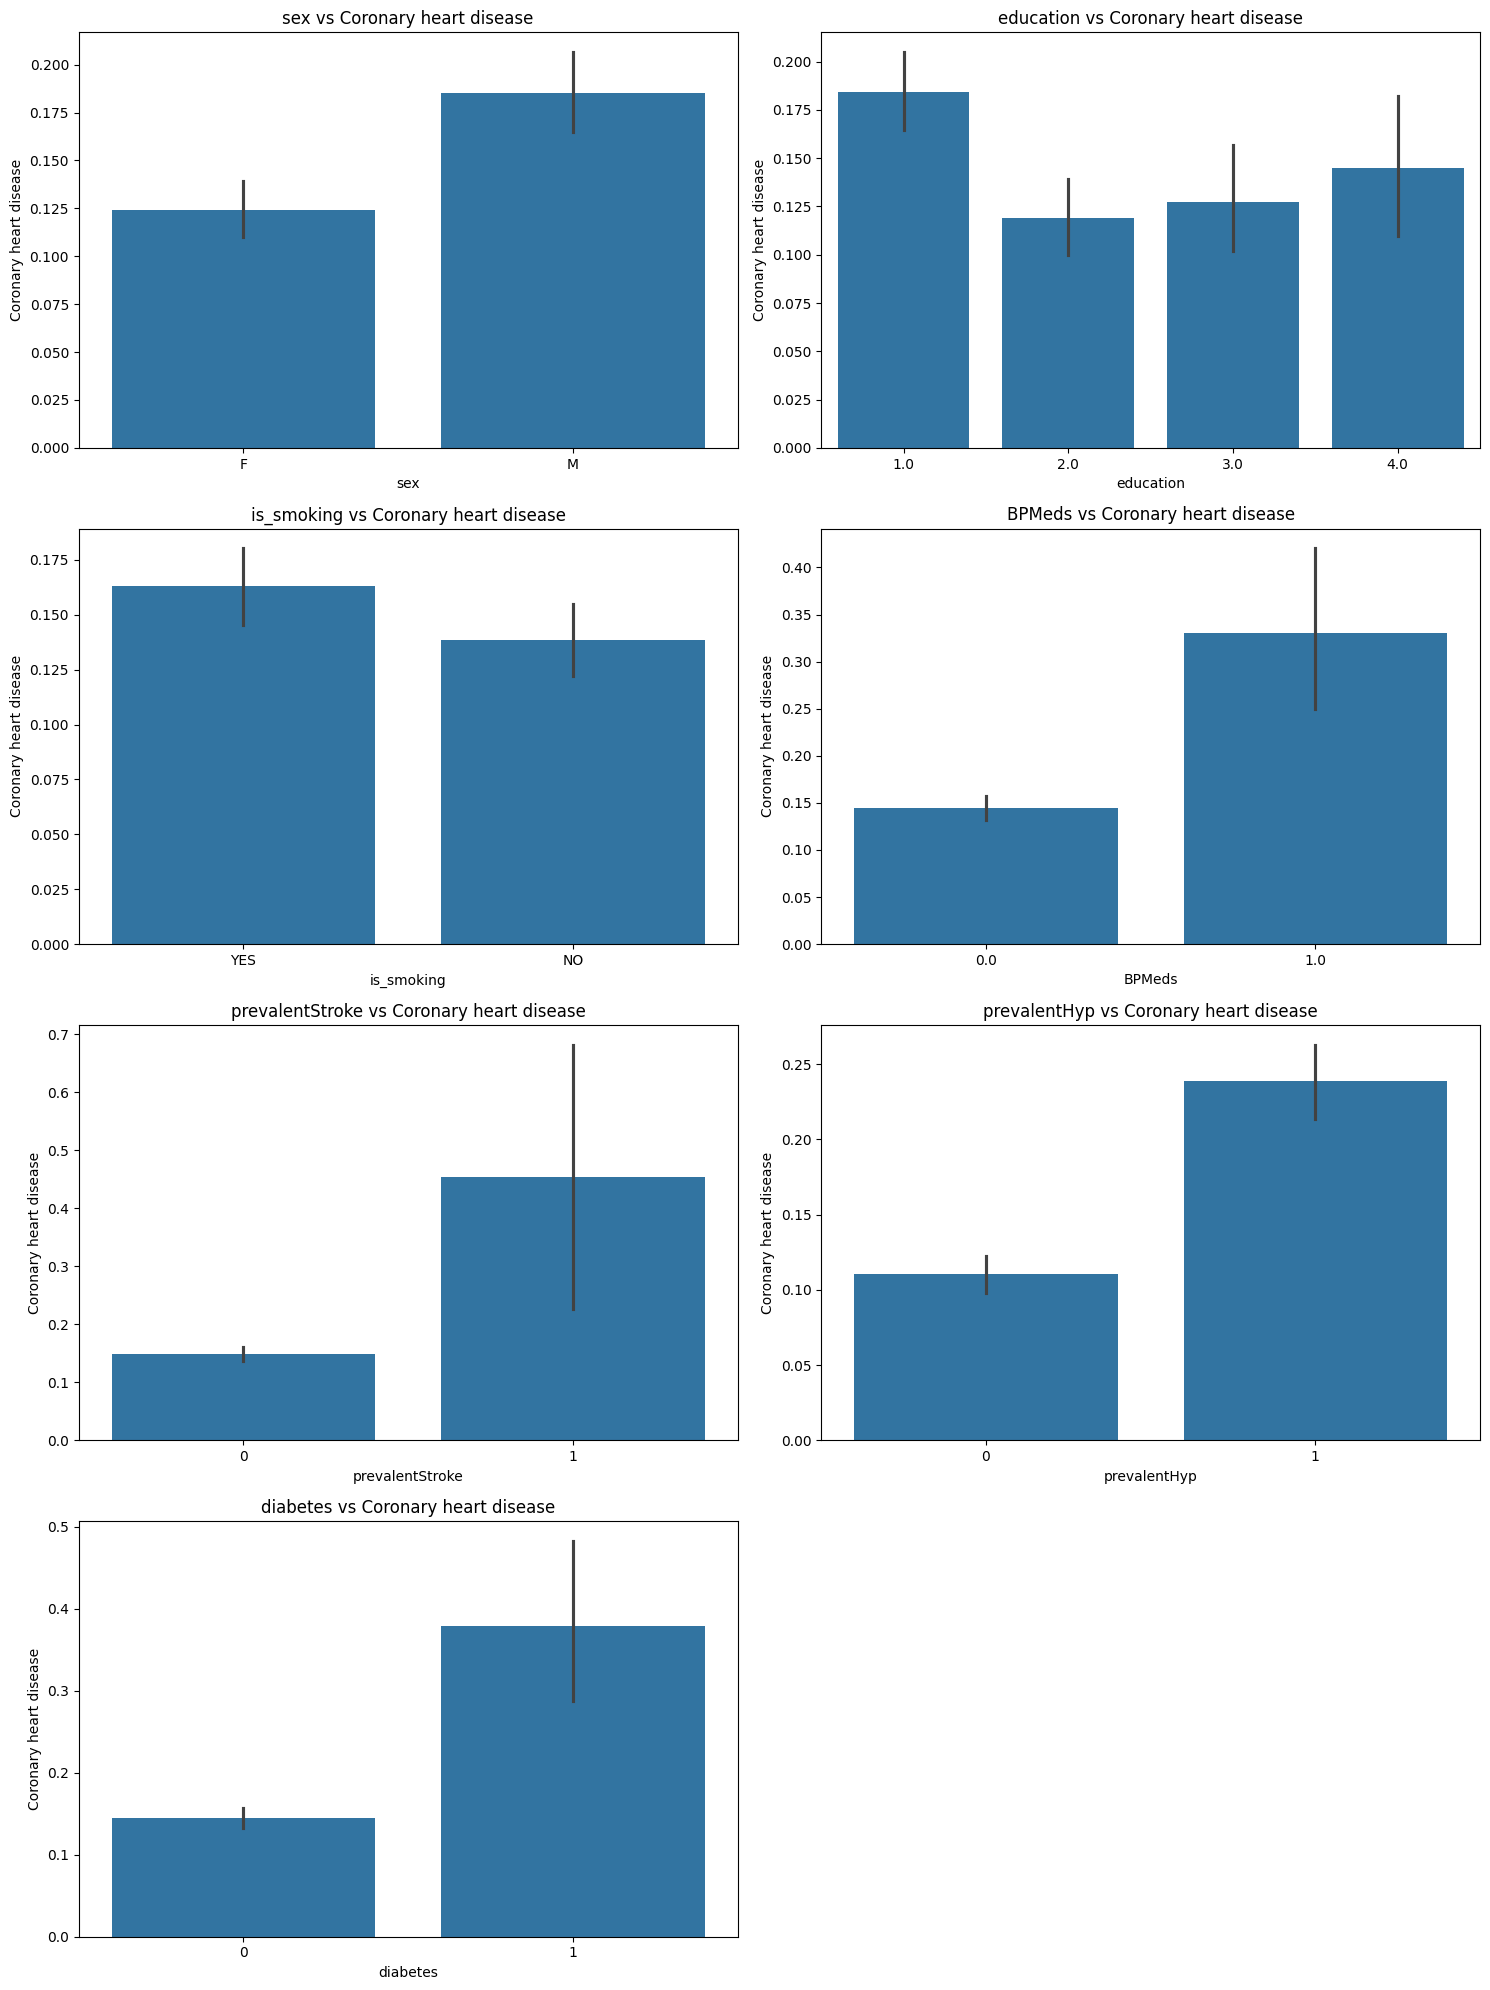

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the list of categorical columns
categorical_columns = ['sex', 'education', 'is_smoking', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes']

# Define the target column
target_column = 'Coronary heart disease'

def plot_categorical_distributions(df, columns):
    n_cols = 2
    n_rows = (len(columns) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
    if n_rows > 1:
        axes = axes.flatten()
    else:
        axes = [axes] if n_cols == 1 else axes
    
    for i, col in enumerate(columns):
        sns.countplot(x=col, data=df, ax=axes[i])
        axes[i].set_title(f'Distribution of {col}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Count')
        
        # Add percentage labels
        total = float(len(df))
        for p in axes[i].patches:
            height = p.get_height()
            axes[i].text(p.get_x() + p.get_width()/2., height,
                         f'{height/total:.1%}',
                         ha='center', va='bottom')
    
    # Hide unused subplots
    for j in range(len(columns), len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

def plot_categorical_vs_target(df, categorical_columns, target_column):
    n_cols = 2
    n_rows = (len(categorical_columns) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
    if n_rows > 1:
        axes = axes.flatten()
    else:
        axes = [axes] if n_cols == 1 else axes
    
    for i, col in enumerate(categorical_columns):
        sns.barplot(x=col, y=target_column, data=df, ax=axes[i])
        axes[i].set_title(f'{col} vs {target_column}')
        axes[i].set_xlabel(col)
        axes[i].set_ylabel(target_column)
    
    # Hide unused subplots
    for j in range(len(categorical_columns), len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

# Now, let's call these functions
print("Analyzing categorical variable distributions:")
plot_categorical_distributions(df, categorical_columns)

print("\nAnalyzing categorical variables vs target:")
plot_categorical_vs_target(df, categorical_columns, target_column)

## 2.4 Numerical Variables vs Target


Insights for age vs Coronary heart disease:
Median age for non-CHD group: 48.00
Median age for CHD group: 55.00
Difference: 7.00 (14.6%)

Insights for cigsPerDay vs Coronary heart disease:
Median cigsPerDay for non-CHD group: 0.00
Median cigsPerDay for CHD group: 3.00
Difference: 3.00 (inf%)

Insights for totChol vs Coronary heart disease:
Median totChol for non-CHD group: 232.00
Median totChol for CHD group: 244.00
Difference: 12.00 (5.2%)

Insights for sysBP vs Coronary heart disease:
Median sysBP for non-CHD group: 127.50
Median sysBP for CHD group: 139.00
Difference: 11.50 (9.0%)

Insights for diaBP vs Coronary heart disease:
Median diaBP for non-CHD group: 81.00
Median diaBP for CHD group: 85.00
Difference: 4.00 (4.9%)

Insights for BMI vs Coronary heart disease:
Median BMI for non-CHD group: 25.23
Median BMI for CHD group: 26.19
Difference: 0.96 (3.8%)

Insights for heartRate vs Coronary heart disease:
Median heartRate for non-CHD group: 75.00
Median heartRate for CHD group: 75.

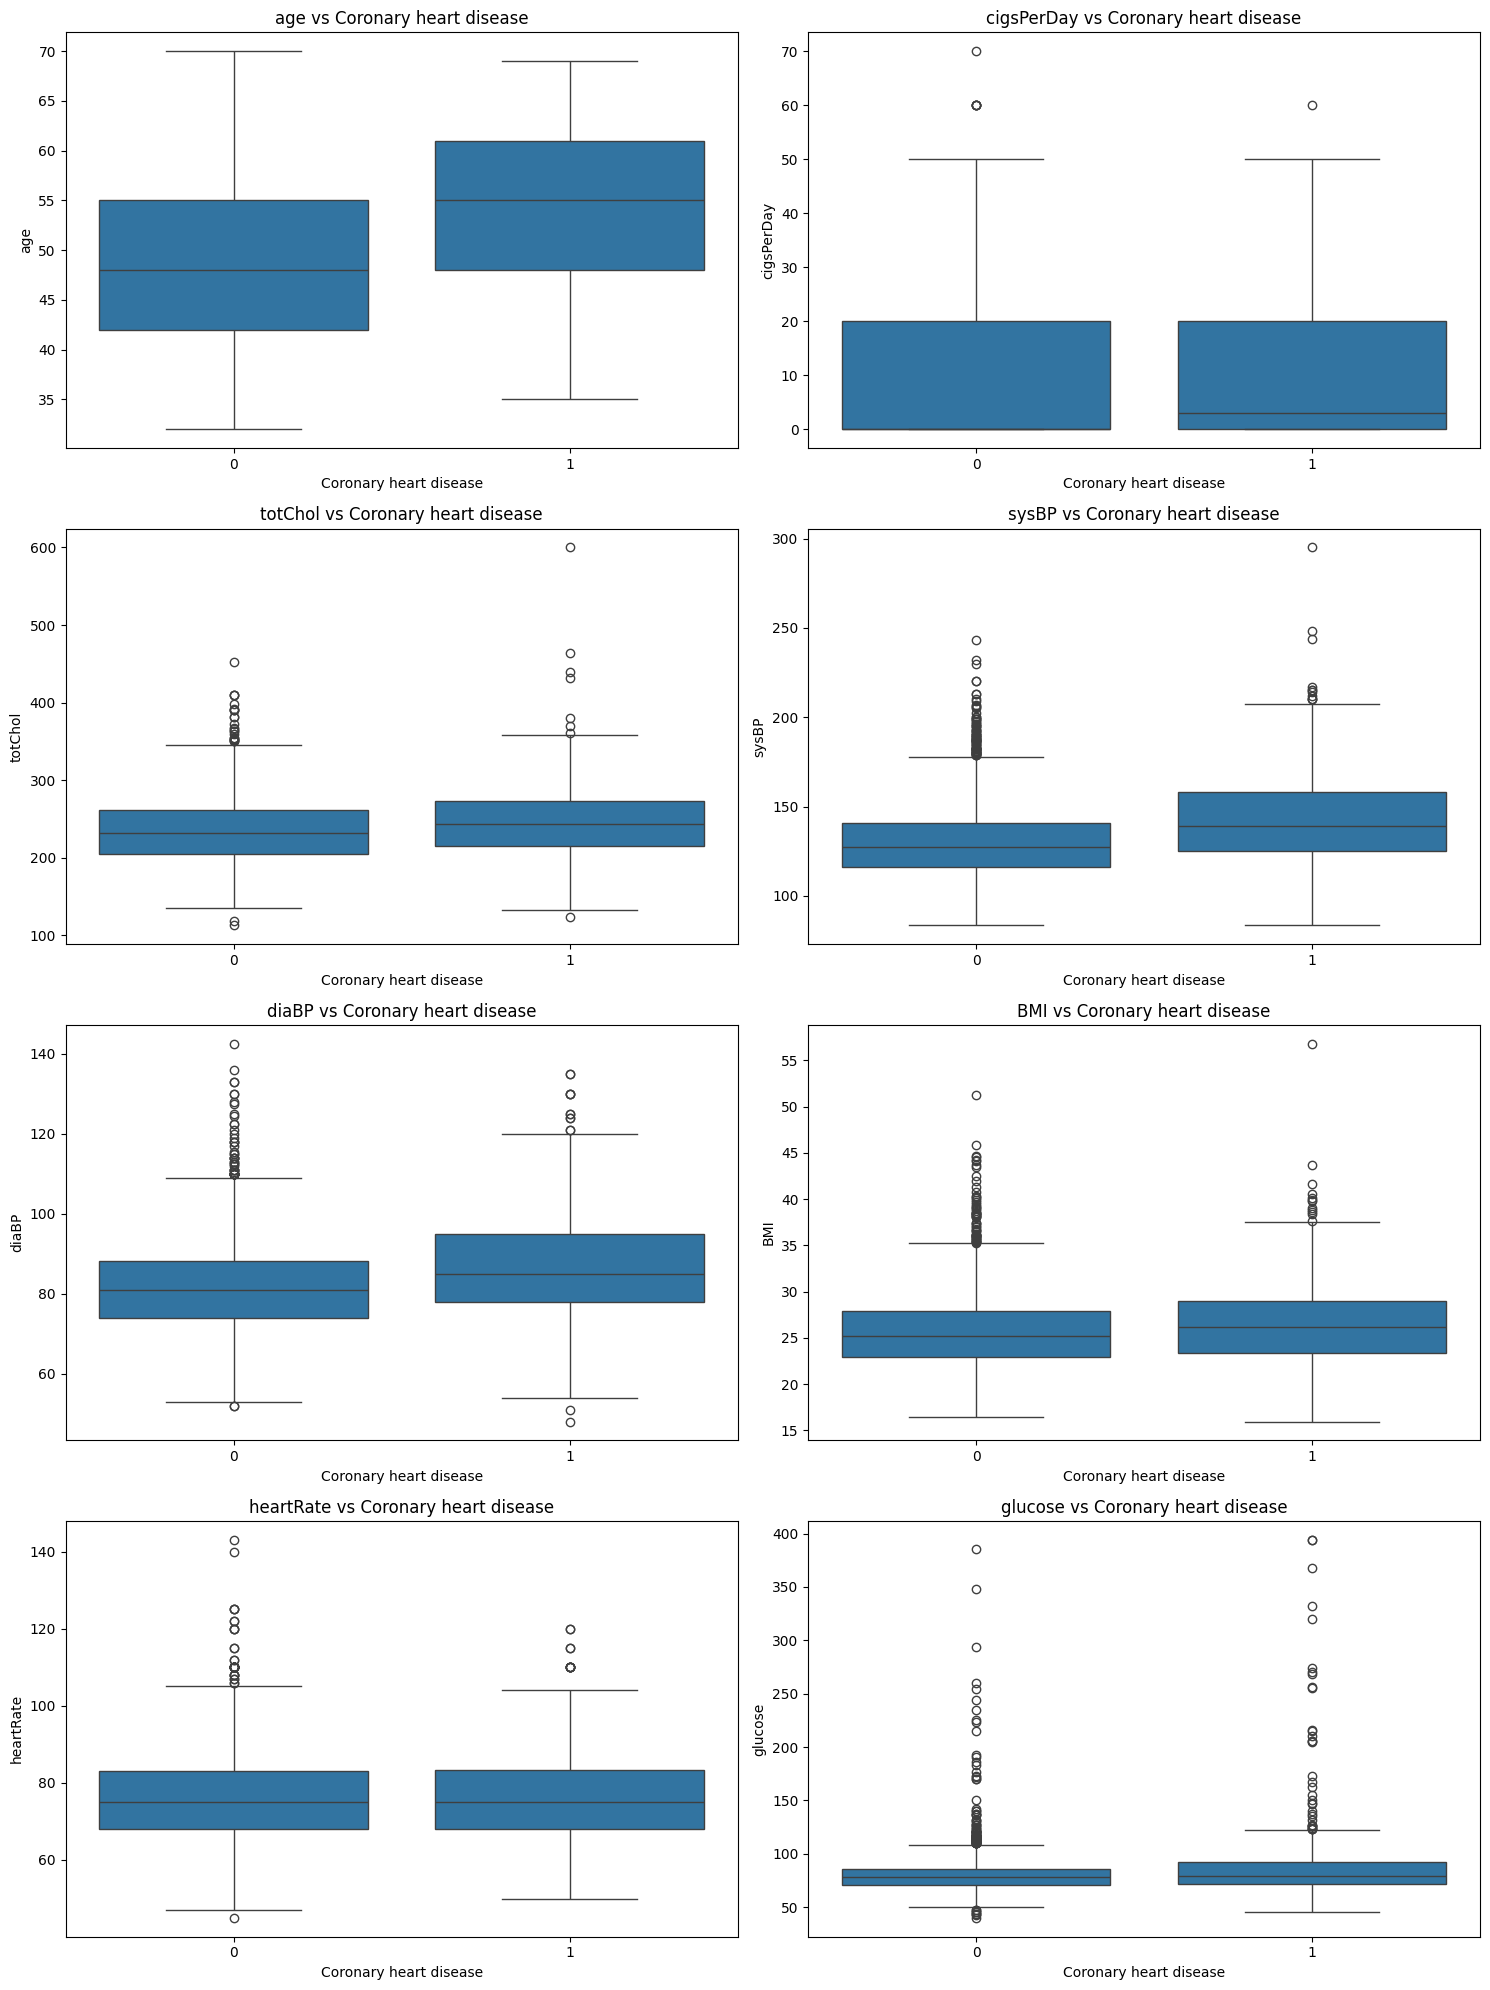

In [10]:
def plot_numerical_vs_target(df, numerical_columns, target_column):
    """
    Plot the relationship between numerical variables and the target variable, and provide insights.
    
    Args:
    df (pd.DataFrame): Input dataset
    numerical_columns (list): List of numerical column names
    target_column (str): Name of the target column
    """
    n_cols = 2
    n_rows = (len(numerical_columns) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_columns):
        sns.boxplot(x=target_column, y=col, data=df, ax=axes[i])
        axes[i].set_title(f'{col} vs {target_column}')
        axes[i].set_xlabel(target_column)
        axes[i].set_ylabel(col)
        
        # Add insights
        print(f"\nInsights for {col} vs {target_column}:")
        grouped = df.groupby(target_column)[col].median()
        difference = grouped[1] - grouped[0]
        percent_difference = (difference / grouped[0]) * 100
        
        print(f"Median {col} for non-CHD group: {grouped[0]:.2f}")
        print(f"Median {col} for CHD group: {grouped[1]:.2f}")
        print(f"Difference: {difference:.2f} ({percent_difference:.1f}%)")
        
        
    
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    
    plt.tight_layout()
    plt.show()

    # Define the numerical columns
numerical_columns = ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']

# Define the target column
target_column = 'Coronary heart disease'

# Now, let's call the function
plot_numerical_vs_target(df_clean, numerical_columns, target_column)

## 2.5 Pairplot

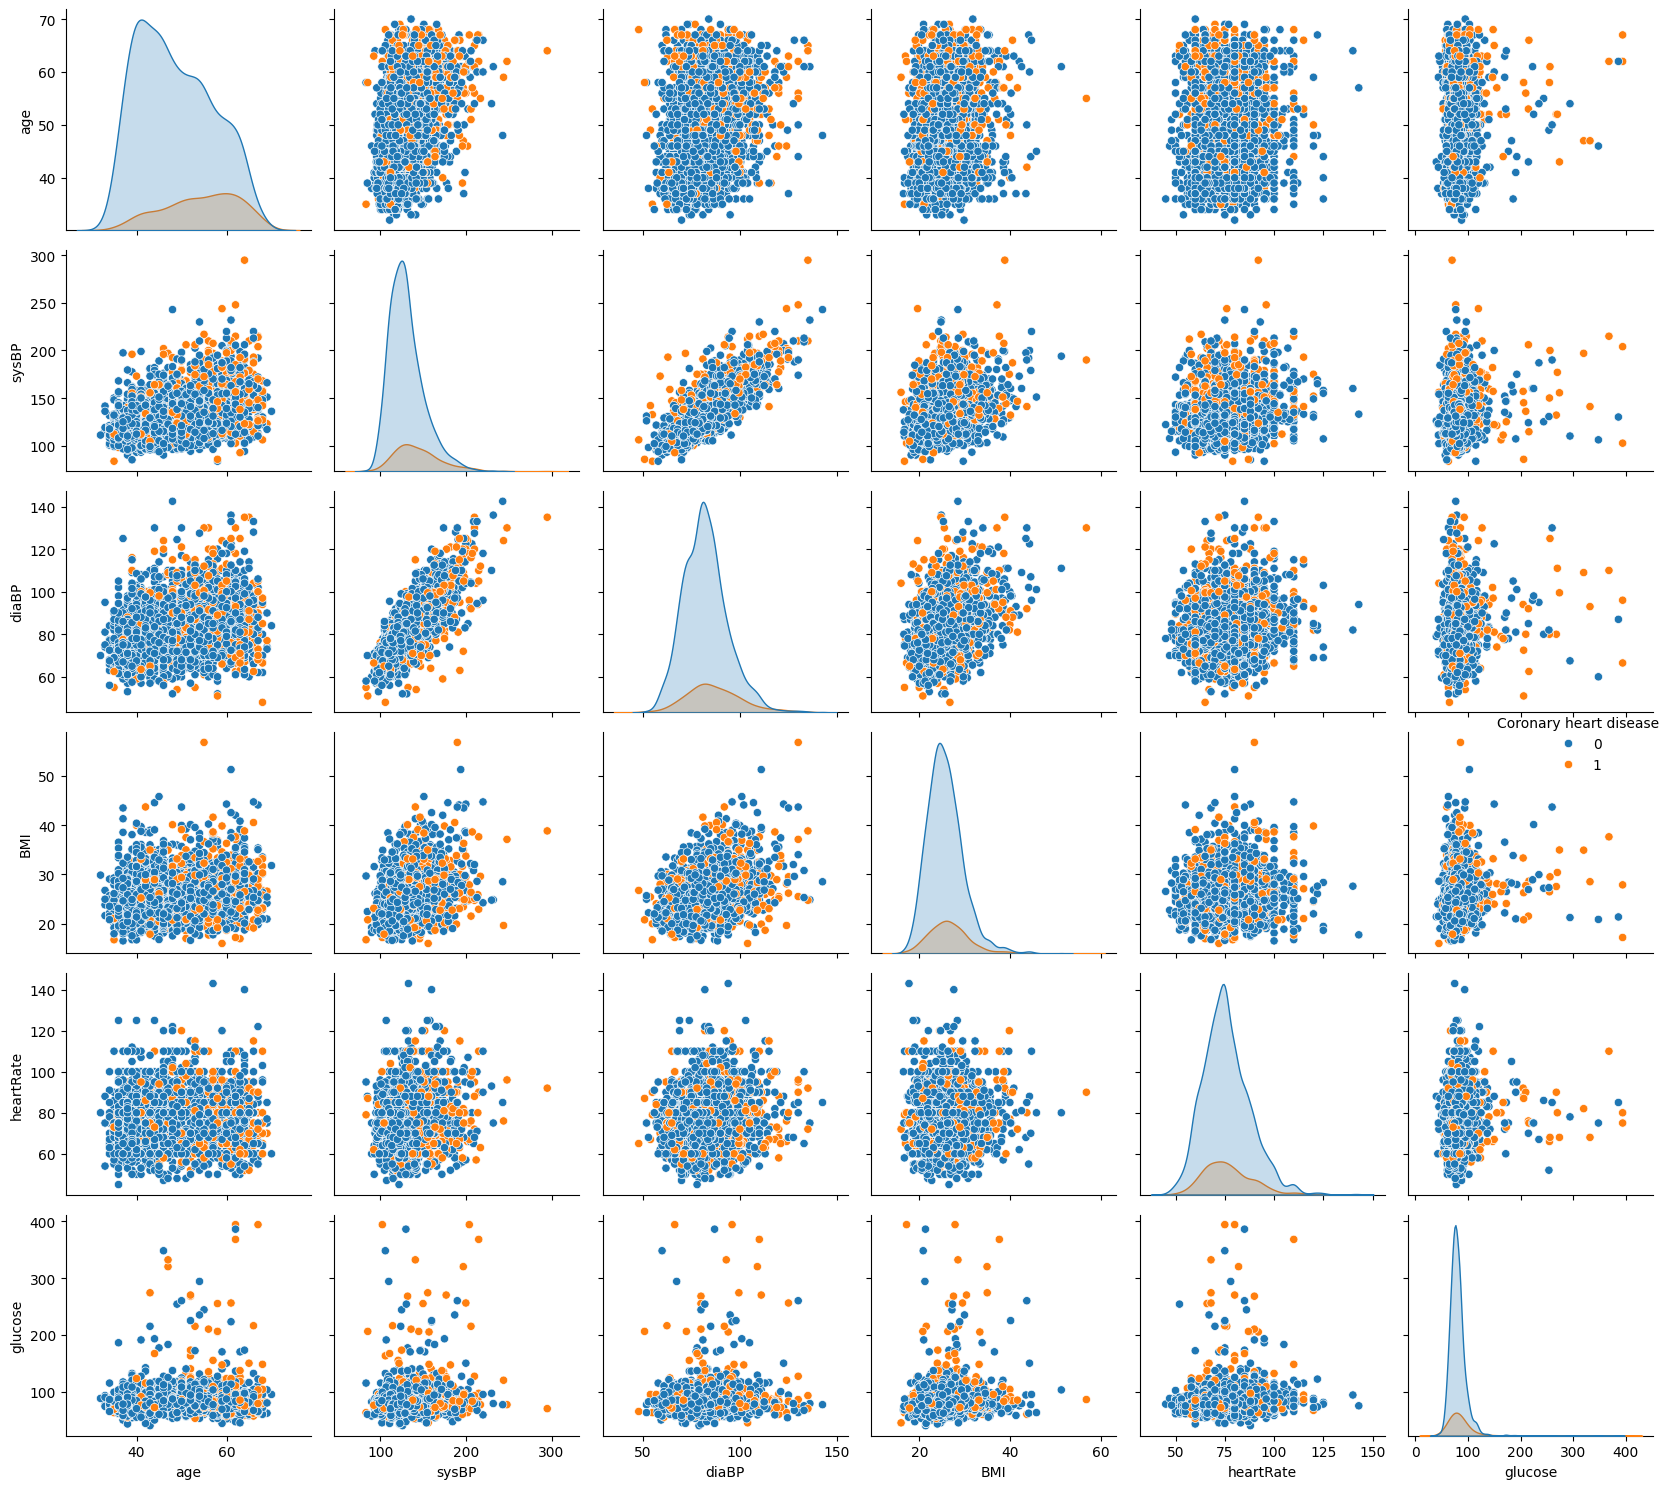


Insights from the pairplot:
1. Look for clear separations between CHD and non-CHD points in any of the scatter plots.
2. Diagonal plots show the distribution of each variable, split by CHD status.
3. Off-diagonal plots show relationships between pairs of variables, color-coded by CHD status.
4. Any visible patterns or clusters might indicate important relationships for predicting CHD.


In [11]:
def plot_pairplot(df, columns, hue):
    """
    Create a pairplot to visualize relationships between multiple variables and provide insights.
    
    Args:
    df (pd.DataFrame): Input dataset
    columns (list): List of column names to include in the pairplot
    hue (str): Column name to use for color-coding the points
    """
    sns.pairplot(df[columns + [hue]], hue=hue, height=2.5)
    plt.tight_layout()
    plt.show()
    
    print("\nInsights from the pairplot:")
    print("1. Look for clear separations between CHD and non-CHD points in any of the scatter plots.")
    print("2. Diagonal plots show the distribution of each variable, split by CHD status.")
    print("3. Off-diagonal plots show relationships between pairs of variables, color-coded by CHD status.")
    print("4. Any visible patterns or clusters might indicate important relationships for predicting CHD.")

# We'll choose key risk factors for CHD
pairplot_columns = ['age', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']

# Define the target column (this will be used as the hue)
hue_column = 'Coronary heart disease'

# Now, let's call the function
plot_pairplot(df_clean, pairplot_columns, hue_column)

## 2.6 Age Distribution Analysis

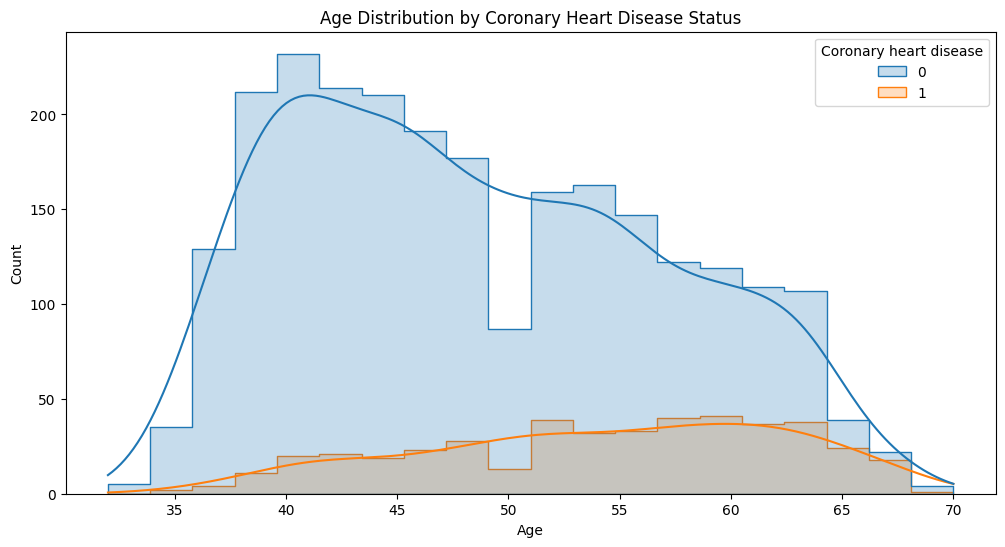


Age statistics by CHD status:
                         count       mean       std   min   25%   50%   75%  \
Coronary heart disease                                                        
0                       2483.0  48.655256  8.397961  32.0  42.0  48.0  55.0   
1                        444.0  54.272523  8.137646  35.0  48.0  55.0  61.0   

                         max  
Coronary heart disease        
0                       70.0  
1                       69.0  

Insights from age distribution analysis:
1. Mean age for non-CHD group: 48.66
2. Mean age for CHD group: 54.27
3. The CHD group is on average 5.62 years older than the non-CHD group.
   This suggests a strong relationship between age and CHD risk.
4. Look at the shape of the distributions: Is the CHD distribution shifted to the right (older ages)?
5. Consider the age range of the study population and how it might affect the generalizability of the results.


In [12]:
def analyze_age_distribution(df):
    """
    Analyze and plot the age distribution in relation to CHD, and provide insights.
    
    Args:
    df (pd.DataFrame): Input dataset
    """
    plt.figure(figsize=(12, 6))
    sns.histplot(data=df, x='age', hue='Coronary heart disease', kde=True, element='step')
    plt.title('Age Distribution by Coronary Heart Disease Status')
    plt.xlabel('Age')
    plt.ylabel('Count')
    plt.show()
    
    print("\nAge statistics by CHD status:")
    age_stats = df.groupby('Coronary heart disease')['age'].describe()
    print(age_stats)
    
    print("\nInsights from age distribution analysis:")
    print(f"1. Mean age for non-CHD group: {age_stats.loc[0, 'mean']:.2f}")
    print(f"2. Mean age for CHD group: {age_stats.loc[1, 'mean']:.2f}")
    
    age_difference = age_stats.loc[1, 'mean'] - age_stats.loc[0, 'mean']
    print(f"3. The CHD group is on average {age_difference:.2f} years older than the non-CHD group.")
    
    if age_difference > 5:
        print("   This suggests a strong relationship between age and CHD risk.")
    else:
        print("   The age difference between groups is relatively small, suggesting other factors might be more important.")
    
    print("4. Look at the shape of the distributions: Is the CHD distribution shifted to the right (older ages)?")
    print("5. Consider the age range of the study population and how it might affect the generalizability of the results.")

# Usage
analyze_age_distribution(df_clean)

# 3.Data Preparation for Modeling

In [13]:
categorical_features=df_encoded[['sex','is_smoking','BPMeds','prevalentStroke','prevalentHyp','diabetes']]
categorical_features

,sex,is_smoking,BPMeds,prevalentStroke,prevalentHyp,diabetes
Patient ID,,,,,,
1,1,0,0.0,0,1,0
2,0,1,0.0,0,0,0
3,1,1,0.0,0,1,0
4,0,1,0.0,0,0,0
5,0,0,0.0,0,1,0
...,...,...,...,...,...,...
3384,0,0,0.0,0,1,0
3385,0,0,0.0,0,0,0
3386,0,0,0.0,0,0,0


## WE use chi square to find out the relationship betwwen categorical feature with Target 

In [14]:
from sklearn.feature_selection import chi2
X = categorical_features
y = df_encoded['Coronary heart disease']
chi_scores = chi2(X, y)
chi_scores

(array([10.86106465,  1.64527101, 24.4846018 ,  7.87008359, 57.41396234,
        28.48354153]),
 array([9.82072196e-04, 1.99603796e-01, 7.49060905e-07, 5.02593299e-03,
        3.53091810e-14, 9.44983806e-08]))

### A high chi value means that there is a significant statistical relationship between the feature and the target variable. 
### Therefore we can include these features to train  model.

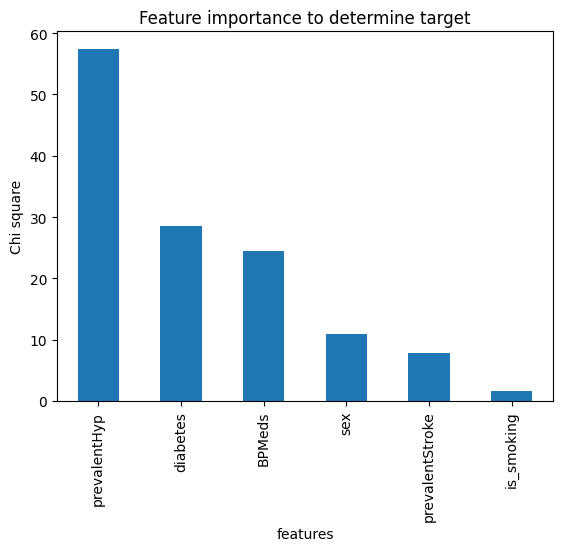

In [15]:
# higher the chi value, higher the importance feature it is
chi_values = pd.Series(chi_scores[0], index=X.columns)
chi_values.sort_values(ascending=False, inplace=True)
chi_values.plot.bar()
plt.xlabel( 'features')
plt.ylabel('Chi square')
plt.title('Feature importance to determine target')
plt.show()

<Axes: >

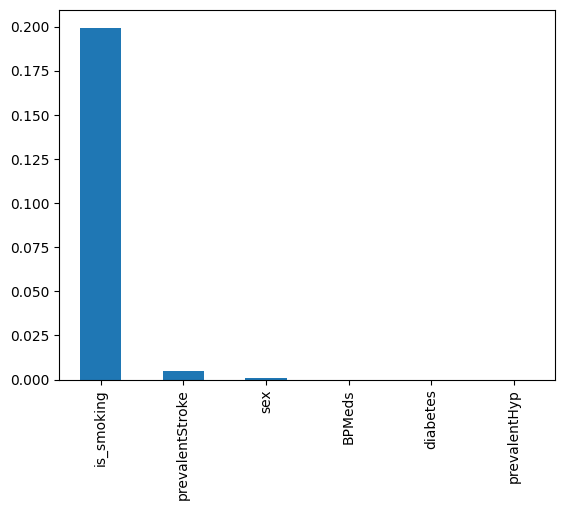

In [16]:
# if p-value > 0.05, lower the importance
p_values = pd.Series(chi_scores[1], index=X.columns)
p_values.sort_values(ascending=False, inplace=True)
p_values.plot.bar()

In [17]:
col=['age', 'education', 'sex', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose']
X=df_encoded[col]
y=df_encoded['Coronary heart disease']


print(f'features shape {X.shape}')
print(f'target shape {y.shape}')

features shape (2927, 14)
target shape (2927,)


### from data we have small number of those who have CHD
### we need to deal with this imbalance of class to help our model to generalize well
### so we use SMOTE technique

In [18]:
num_before = dict(Counter(y))

# Perform SMOTE

over=SMOTE(sampling_strategy=0.8)
under=RandomUnderSampler(sampling_strategy=0.8)
steps=[("o",over),("u",under)]
# Define Pipeline
pipeline = Pipeline(steps=steps)

# Transform the dataset
X_smote,y_smote=pipeline.fit_resample(X,y)

# The numbers after SMOTE
num_after=dict(Counter(y_smote))

## Plot showing data in class before and after applying SMOTE

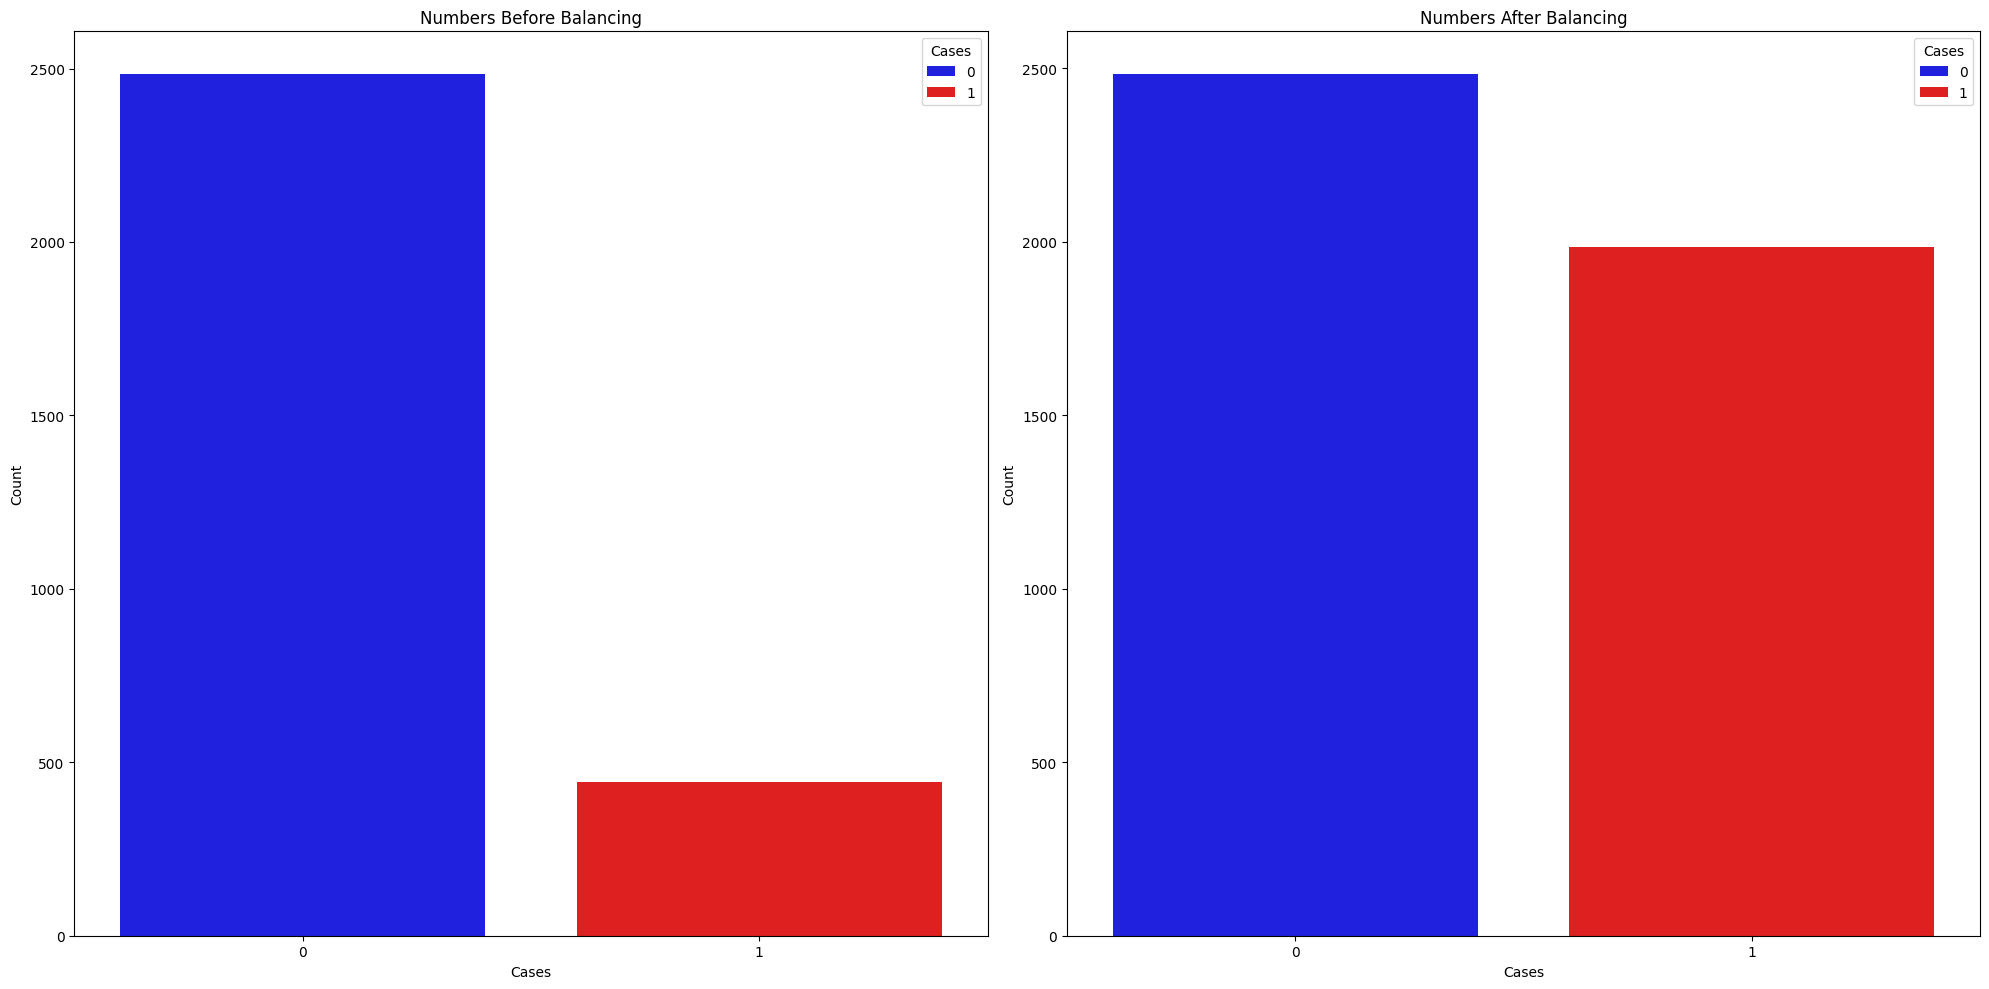

In [19]:
# Create DataFrame for num_before
data_before = pd.DataFrame(list(num_before.items()), columns=['Cases', 'Count'])

# Create DataFrame for num_after
data_after = pd.DataFrame(list(num_after.items()), columns=['Cases', 'Count'])

# Set the figure size
plt.figure(figsize=(20, 10))

# Create subplots
plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
sns.barplot(x='Cases', y='Count',hue='Cases', data=data_before, palette=['blue', 'red'])
plt.title('Numbers Before Balancing')


plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
sns.barplot(x='Cases', y='Count', hue='Cases',data=data_after, palette=['blue', 'red'])
plt.title('Numbers After Balancing')


# Show the plots
plt.tight_layout()  # Adjust the layout
plt.show()

## Exploration of new data we got

In [20]:
new_data = pd.concat([pd.DataFrame(X_smote), pd.DataFrame(y_smote)], axis=1)
new_data.info()
new_data.shape
new_data.head()

<class 'pandas.core.frame.DataFrame'>
Index: 4468 entries, 295 to 4468
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     4468 non-null   int64  
 1   education               4468 non-null   float64
 2   sex                     4468 non-null   int32  
 3   cigsPerDay              4468 non-null   float64
 4   BPMeds                  4468 non-null   float64
 5   prevalentStroke         4468 non-null   int64  
 6   prevalentHyp            4468 non-null   int64  
 7   diabetes                4468 non-null   int64  
 8   totChol                 4468 non-null   float64
 9   sysBP                   4468 non-null   float64
 10  diaBP                   4468 non-null   float64
 11  BMI                     4468 non-null   float64
 12  heartRate               4468 non-null   float64
 13  glucose                 4468 non-null   float64
 14  Coronary heart disease  4468 non-null   int

,age,education,sex,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,Coronary heart disease
295,56,1.0,0,0.0,0.0,0,1,0,262.0,150.0,89.0,40.21,75.0,86.0,0
2196,44,1.0,0,8.0,0.0,0,0,0,351.0,106.0,65.0,25.34,95.0,69.0,0
2778,45,2.0,0,0.0,0.0,0,1,0,258.0,148.5,88.0,23.46,85.0,90.0,0
1680,48,1.0,0,0.0,0.0,0,0,0,225.0,132.0,80.0,21.35,60.0,74.0,0
1683,60,1.0,1,0.0,0.0,0,0,0,275.0,132.0,82.0,23.53,75.0,62.0,0


In [21]:
X_new = new_data.iloc[:, 0:14]
y_new= new_data.iloc[:,-1]
X_new.head()

,age,education,sex,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
295,56,1.0,0,0.0,0.0,0,1,0,262.0,150.0,89.0,40.21,75.0,86.0
2196,44,1.0,0,8.0,0.0,0,0,0,351.0,106.0,65.0,25.34,95.0,69.0
2778,45,2.0,0,0.0,0.0,0,1,0,258.0,148.5,88.0,23.46,85.0,90.0
1680,48,1.0,0,0.0,0.0,0,0,0,225.0,132.0,80.0,21.35,60.0,74.0
1683,60,1.0,1,0.0,0.0,0,0,0,275.0,132.0,82.0,23.53,75.0,62.0


## Split the data into traing and tesing set

In [22]:
X_train,X_test,y_train,y_test = train_test_split(X_new,y_new,test_size=0.2,random_state=42)

# Normalize/ Scale the data 

In [23]:
# Capture column names
column_names = X_train.columns

# Scale the data
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=column_names, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=column_names, index=X_test.index)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

print(X_train_scaled.head())

(3574, 14)
(894, 14)
           age  education       sex  cigsPerDay    BPMeds  prevalentStroke  \
1588  0.352014   0.089483 -0.832488   -0.801614 -0.226396        -0.058042   
2887  0.352014   0.089483  1.201218   -0.801614 -0.226396        -0.058042   
608   0.352014   0.089483 -0.832488   -0.801614 -0.226396        -0.058042   
4123  0.233359  -0.443155  1.201218    1.319741 -0.226396        -0.058042   
2513 -1.783776   2.173644  1.201218   -0.801614 -0.226396        -0.058042   

      prevalentHyp  diabetes   totChol     sysBP     diaBP       BMI  \
1588     -0.709185 -0.200407  0.643705 -1.593810 -1.596808 -0.974686   
2887     -0.709185 -0.200407 -1.000857 -0.167308 -0.053755  0.054277   
608       1.410069 -0.200407  0.249010  0.420075  0.223203  1.748751   
4123     -0.709185 -0.200407 -0.979418 -0.761212 -0.886391 -1.157556   
2513     -0.709185 -0.200407 -1.022784 -0.796647  0.460595  0.267928   

      heartRate   glucose  
1588  -0.782963 -0.306477  
2887  -0.083827  0.45

In [24]:
X_train.head()

,age,education,sex,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
1588,54,2.000000,0,0.000000,0.0,0,0,0,270.000000,98.000000,64.000000,22.020000,67.000000,75.000000
2887,54,2.000000,1,0.000000,0.0,0,0,0,195.000000,132.000000,83.500000,26.210000,75.000000,100.000000
608,54,2.000000,0,0.000000,0.0,0,1,0,252.000000,146.000000,87.000000,33.110000,90.000000,100.000000
4123,53,1.488871,1,24.888709,0.0,0,0,0,195.977742,117.844598,72.977742,21.275342,85.910967,72.310805
2513,36,4.000000,1,0.000000,0.0,0,0,0,194.000000,117.000000,90.000000,27.080000,73.000000,87.000000


In [25]:
X_test.head()

,age,education,sex,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
4174,64,3.46654,1,0.0,0.0,0,0,0,210.711280,123.800191,80.822180,25.711148,61.600381,76.600381
1538,64,2.00000,0,3.0,0.0,0,0,0,315.000000,135.000000,80.000000,25.230000,103.000000,89.000000
3014,54,1.00000,0,0.0,0.0,0,0,0,261.902548,128.592803,77.522039,25.562366,61.424587,72.283058
1467,40,2.00000,1,30.0,1.0,0,1,0,287.000000,141.000000,86.000000,27.420000,80.000000,94.000000
3214,60,2.00000,0,15.0,0.0,0,1,0,234.664445,154.025812,93.961282,23.050417,69.922564,66.051624


# 4.Model Development and Evaluation:

## 4.1 Logistic Regression

Best Hyperparameters: {'logistic__C': 10, 'logistic__max_iter': 100, 'logistic__penalty': 'l1', 'logistic__solver': 'liblinear'}
Best Cross-validation Score: 0.6636861178037649
Training Accuracy: 0.6648
Testing Accuracy: 0.6790

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.77      0.73       505
           1       0.65      0.57      0.61       389

    accuracy                           0.68       894
   macro avg       0.67      0.67      0.67       894
weighted avg       0.68      0.68      0.68       894



<Figure size 1000x800 with 0 Axes>

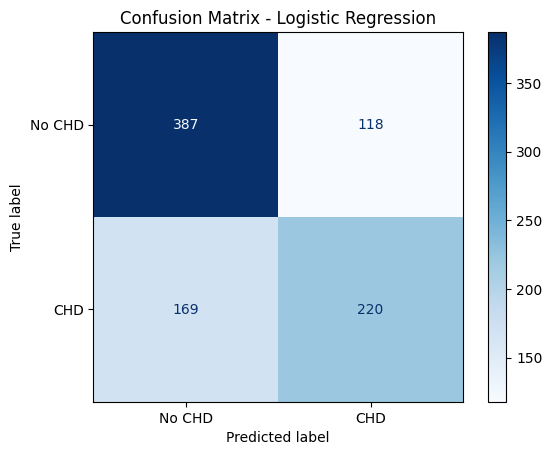

In [26]:
param_grid = {
    'logistic__C': [0.01, 0.1, 1, 10, 100],
    'logistic__penalty': ['l1', 'l2'],
    'logistic__solver': ['liblinear', 'saga'],
    'logistic__max_iter': [100, 200, 300]
}

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression())
])

grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-validation Score:", grid_search.best_score_)

# Calculate training accuracy
y_train_pred = grid_search.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"Training Accuracy: {train_accuracy:.4f}")

# Calculate testing accuracy
y_test_pred = grid_search.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Testing Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# Plot confusion matrix
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay.from_estimator(grid_search, X_test, y_test, display_labels=['No CHD', 'CHD'], cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

## 4.2 K-Nearest Neighbors (KNN)

Best Hyperparameters:  {'n_neighbors': 2}
Training Accuracy: 0.9885
Testing Accuracy: 0.8635

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.80      0.87       505
           1       0.78      0.95      0.86       389

    accuracy                           0.86       894
   macro avg       0.87      0.87      0.86       894
weighted avg       0.88      0.86      0.86       894



<Figure size 1000x800 with 0 Axes>

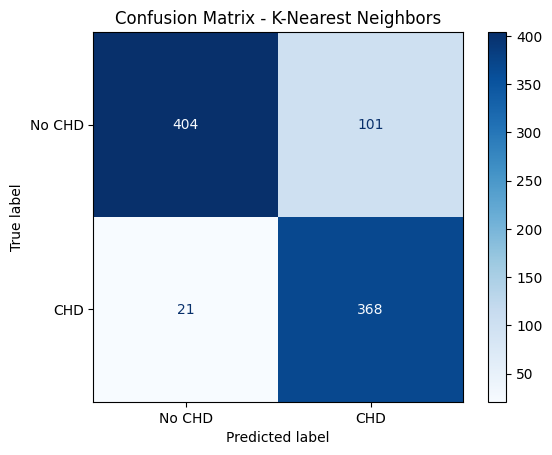

In [27]:
params = {'n_neighbors': np.arange(1, 10)}

grid_search = GridSearchCV(estimator=KNeighborsClassifier(),
                           param_grid=params,
                           scoring='accuracy',
                           cv=10,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

best_knn = grid_search.best_estimator_
print("Best Hyperparameters: ", grid_search.best_params_)

# Calculate training accuracy
y_train_pred = best_knn.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"Training Accuracy: {train_accuracy:.4f}")

# Calculate testing accuracy
y_test_pred = best_knn.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Testing Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# Plot confusion matrix
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay.from_estimator(best_knn, X_test, y_test, display_labels=['No CHD', 'CHD'], cmap='Blues')
plt.title('Confusion Matrix - K-Nearest Neighbors')
plt.show()

## 4.4 XGBoost

Best Hyperparameters:  {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}
Confusion Matrix:
[[489  16]
 [ 95 294]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.97      0.90       505
           1       0.95      0.76      0.84       389

    accuracy                           0.88       894
   macro avg       0.89      0.86      0.87       894
weighted avg       0.89      0.88      0.87       894


Accuracy with custom threshold: 0.88

Accuracy with default threshold: 0.88


<Figure size 1000x800 with 0 Axes>

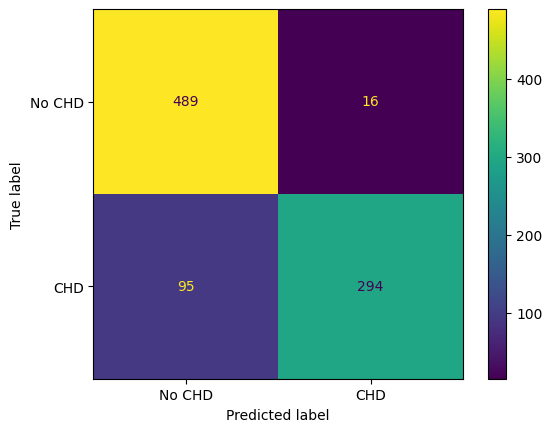

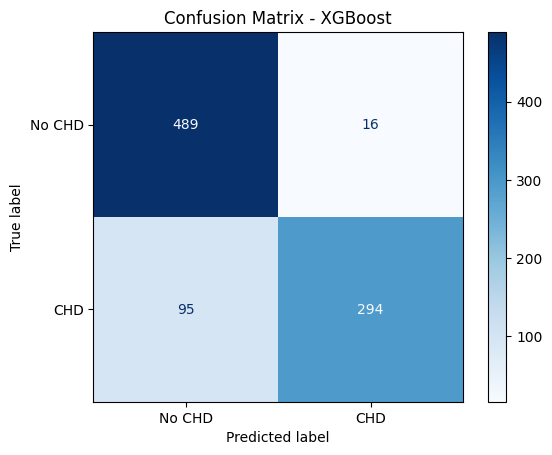

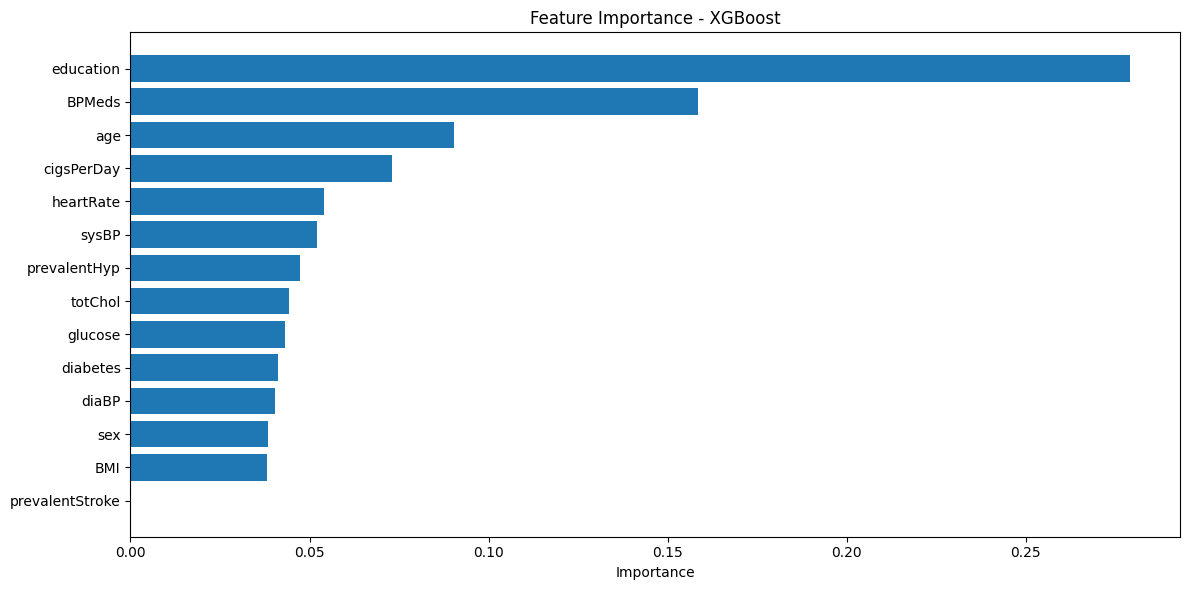

In [28]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Define the parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],  # Number of trees
    'max_depth': [3, 4, 5, 6],       # Maximum depth of the tree
    'learning_rate': [0.01, 0.05, 0.1],  # Step size shrinkage
    'subsample': [0.6, 0.8, 1.0],    # Proportion of samples used for training
    'colsample_bytree': [0.6, 0.8, 1.0]  # Proportion of features used for training
}

# Initialize GridSearchCV with XGBoostClassifier
grid_search_xgb = GridSearchCV(estimator=xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss'),
                                param_grid=param_grid,
                                scoring='accuracy', 
                                cv=5,  # 5-fold cross-validation
                                n_jobs=-1)

# Fit the grid search to the training data
grid_search_xgb.fit(X_train, y_train)

# Get the best XGBoost model
best_xgb = grid_search_xgb.best_estimator_

# Print the best hyperparameters
print("Best Hyperparameters: ", grid_search_xgb.best_params_)

# Predict probabilities for the test set using the best XGBoost model
y_pred_prob = best_xgb.predict_proba(X_test)

# Set a custom threshold (e.g., 0.6)
threshold = 0.6

# Classify based on the custom threshold
y_pred_custom = (y_pred_prob[:, 1] >= threshold).astype(int)

# Confusion matrix and classification report
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_custom))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_custom))

# Accuracy with custom threshold
accuracy_custom = accuracy_score(y_test, y_pred_custom)
print(f"\nAccuracy with custom threshold: {accuracy_custom:.2f}")

# Also, check accuracy with the default threshold (0.5) for comparison
y_pred_default = best_xgb.predict(X_test)
accuracy_default = accuracy_score(y_test, y_pred_default)
print(f"\nAccuracy with default threshold: {accuracy_default:.2f}")

# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm_display = ConfusionMatrixDisplay.from_predictions(y_test, y_pred_custom, display_labels=['No CHD', 'CHD'])
cm_display.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - XGBoost')
plt.show()

# Feature importance plot
feature_importance = best_xgb.feature_importances_
feature_names = X_train.columns
sorted_idx = np.argsort(feature_importance)
pos = np.arange(sorted_idx.shape[0]) + .5

plt.figure(figsize=(12, 6))
plt.barh(pos, feature_importance[sorted_idx], align='center')
plt.yticks(pos, np.array(feature_names)[sorted_idx])
plt.title('Feature Importance - XGBoost')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 4.3 Random Forest

Best Hyperparameters:  {'bootstrap': False, 'criterion': 'gini', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
Confusion Matrix:
[[476  29]
 [ 45 344]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.94      0.93       505
           1       0.92      0.88      0.90       389

    accuracy                           0.92       894
   macro avg       0.92      0.91      0.92       894
weighted avg       0.92      0.92      0.92       894


Accuracy with custom threshold: 0.92

Accuracy with default threshold: 0.92


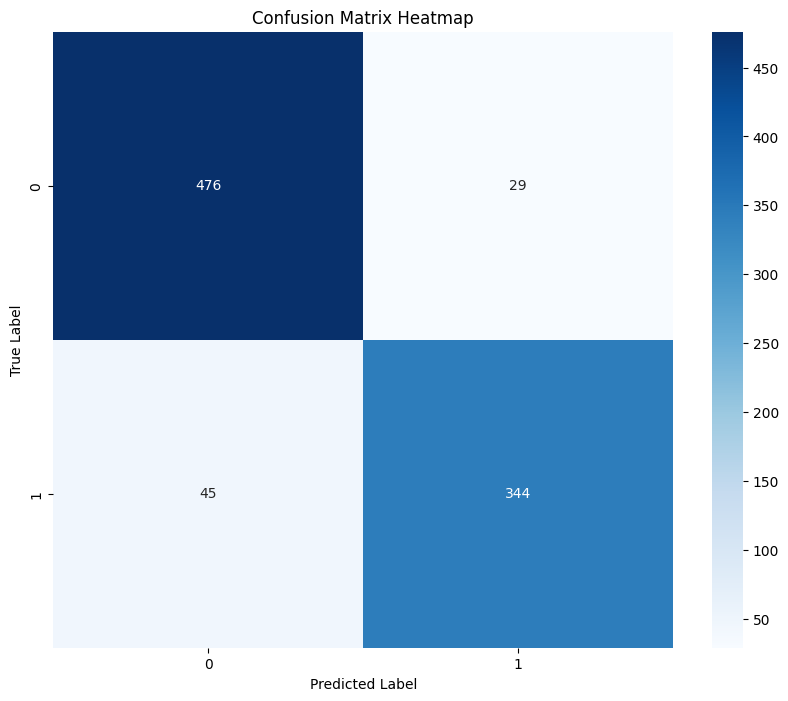

In [29]:

# Define the parameter grid for GridSearchCV
param_grid = {
    'n_estimators': [100, 300, 500],             # Number of trees in the forest
    'max_depth': [10, 20, 30, None],             # Maximum depth of the tree
    'min_samples_split': [2, 5, 10],             # Minimum samples required to split a node
    'min_samples_leaf': [1, 2, 4],               # Minimum samples required at each leaf node
    'bootstrap': [True, False],                  # Method to select samples for training
    'max_features': ['sqrt', 'log2'],            # Number of features to consider for best split
    'criterion': ['gini', 'entropy']             # Split criterion
}

# Use StratifiedKFold for cross-validation
cv = StratifiedKFold(n_splits=5)

# Initialize GridSearchCV with RandomForestClassifier
grid_search_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=42),
                              param_grid=param_grid,
                              scoring='accuracy', 
                              cv=cv,  # 5-fold cross-validation
                              n_jobs=-1)

# Fit the grid search to the training data
grid_search_rf.fit(X_train, y_train)

# Get the best RandomForestClassifier model
best_rf = grid_search_rf.best_estimator_

# Print the best hyperparameters
print("Best Hyperparameters: ", grid_search_rf.best_params_)

# Predict probabilities for the test set using the best Random Forest model
y_pred_prob = best_rf.predict_proba(X_test)

# Set a custom threshold (e.g., 0.6)
threshold = 0.5

# Classify based on the custom threshold
y_pred_custom = (y_pred_prob[:, 1] >= threshold).astype(int)

# Confusion matrix and classification report
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_custom))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_custom))

# Accuracy
accuracy_custom = accuracy_score(y_test, y_pred_custom)
print(f"\nAccuracy with custom threshold: {accuracy_custom:.2f}")

# Also, check accuracy with the default threshold (0.5) for comparison
y_pred_default = best_rf.predict(X_test)
accuracy_default = accuracy_score(y_test, y_pred_default)
print(f"\nAccuracy with default threshold: {accuracy_default:.2f}")


# Confusion matrix heatmap
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred_custom)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix Heatmap')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

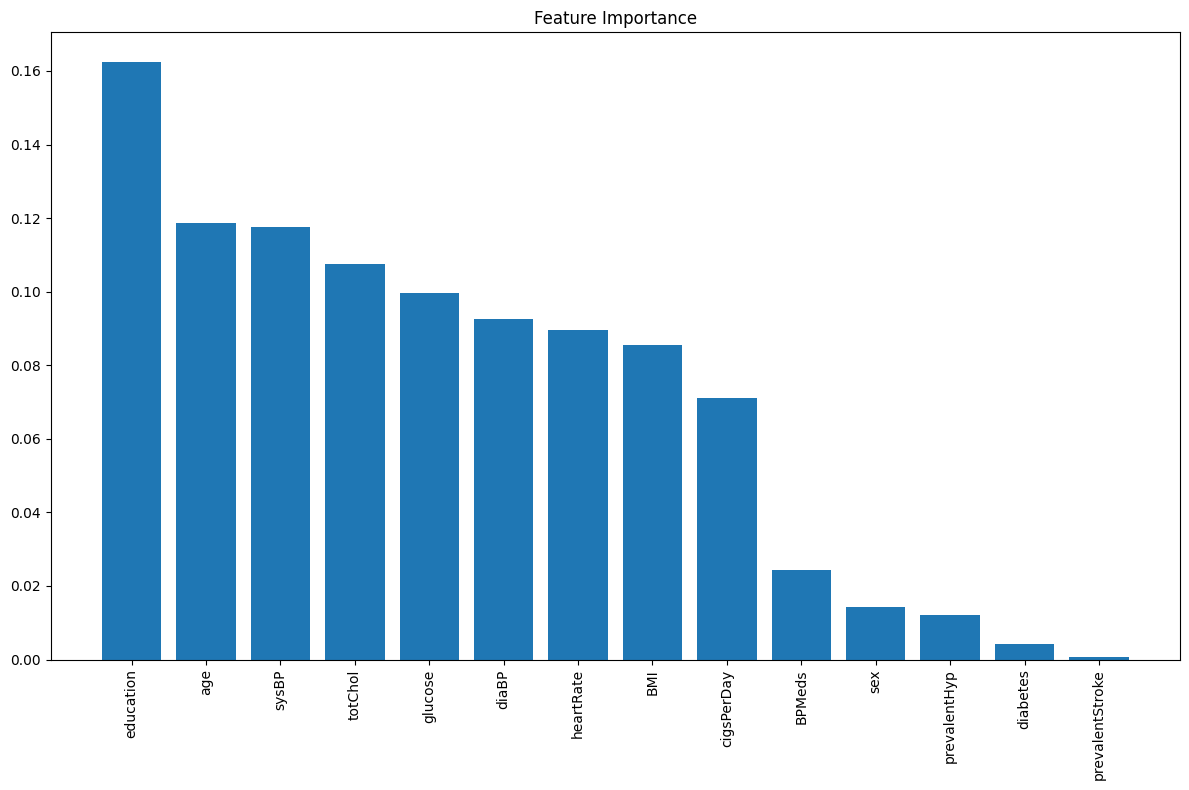


Feature Importances:
education: 0.1624
age: 0.1186
sysBP: 0.1176
totChol: 0.1076
glucose: 0.0997
diaBP: 0.0925
heartRate: 0.0895
BMI: 0.0855
cigsPerDay: 0.0711
BPMeds: 0.0243
sex: 0.0144
prevalentHyp: 0.0120
diabetes: 0.0043
prevalentStroke: 0.0007


In [30]:
# Feature importances
feature_importance = best_rf.feature_importances_
feature_names = X_train.columns

# Sort feature importances in descending order
indices = np.argsort(feature_importance)[::-1]

# Rearrange feature names so they match the sorted feature importances
names = [feature_names[i] for i in indices]

# Create plot
plt.figure(figsize=(12, 8))

# Create plot title
plt.title("Feature Importance")

# Add bars
plt.bar(range(X_train.shape[1]), feature_importance[indices])

# Add feature names as x-axis labels
plt.xticks(range(X_train.shape[1]), names, rotation=90)

# Show plot
plt.tight_layout()
plt.show()

# Print feature importances
print("\nFeature Importances:")
for i, importance in enumerate(feature_importance[indices]):
    print(f"{names[i]}: {importance:.4f}")


In [31]:


# Save the model
joblib.dump(best_rf, 'random_forest_chd_model.joblib')

print("Model saved successfully.")



Model saved successfully.


## 4.5 Support Vector Machine (SVM)

Cross-validation scores: [0.65454545 0.63776224 0.66293706 0.65174825 0.65826331]
Mean CV score: 0.6531

Accuracy on test set: 0.6790

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.79      0.74       505
           1       0.66      0.53      0.59       389

    accuracy                           0.68       894
   macro avg       0.68      0.66      0.66       894
weighted avg       0.68      0.68      0.67       894



<Figure size 800x600 with 0 Axes>

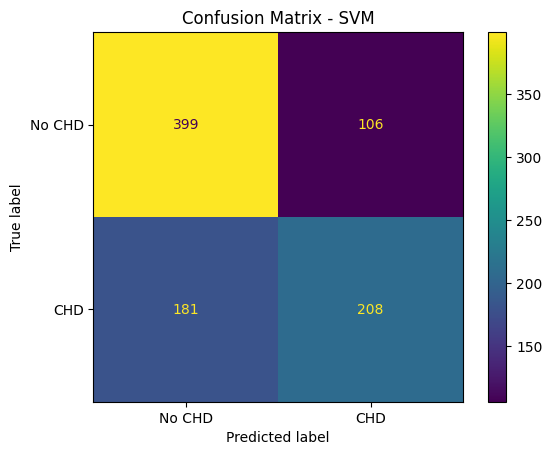

In [32]:
# Initialize SVC with a simpler configuration
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)

# Fit the model
svm_model.fit(X_train, y_train)

# Perform quick cross-validation
cv_scores = cross_val_score(svm_model, X_train, y_train, cv=5)
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean CV score: {cv_scores.mean():.4f}")

# Predict on test set
y_pred = svm_model.predict(X_test)

# Print accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy on test set: {accuracy:.4f}")

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
plt.figure(figsize=(8, 6))
cm_display = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No CHD', 'CHD'])

plt.title('Confusion Matrix - SVM')
plt.show()

# Conclusion: 

## Random Forest Model for Coronary Heart Disease (CHD) Prediction

The Random Forest algorithm demonstrated superior performance in predicting Coronary Heart Disease (CHD) among the models evaluated. Key findings include:

 **Model Performance:**
 
**Accuracy**: 92% on the test set

**Precision**: 92% (weighted average)

**Recall**: 92% (weighted average)

**F1-score**: 92% (weighted average)



**Balanced Performance**: The model shows good balance between precision and recall for both classes, indicating effective handling of the previously imbalanced dataset.

**Potential Applications**: This model could be valuable for initial screening in clinical settings, helping to identify individuals at higher risk of CHD who may require further evaluation or preventive measures.

 **Future Work:**
Feature importance analysis to understand key predictors of CHD

Exploration of ensemble methods combining Random Forest with other high-performing models

Collection of additional relevant features to potentially improve prediction accuracy

Validation on external datasets to ensure generalizability
